# Module 5 · MCMC: Bayesian calibration and mixing
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **Can a simulation explore a parameter's posterior distribution reliably enough to support a model prediction?**

Guided work: about 45–55 minutes. Exercises: about 25–35 minutes. This is **Concept Lab 3, Part A (week 5)**, combined with Module 6 for the week-6 submission. Continue the existing course project.

You will derive a bike-transition posterior, implement Metropolis–Hastings (MH), distinguish posterior uncertainty from numerical error, and challenge mixing with several starts and proposal scales.

[Course home](../index.html) · [Interactive lesson](../modules/module05.html) · [Project guide](../project-guide.html) · [Data provenance](../data/PROVENANCE.md)

Use **Restart Kernel and Run All** from the course root or `notebooks/`. No network, account, API key, or server is needed. Keep exercise answers in the four marked cells; worked examples do not supply those answers.

## 1. Calibrate the same daily-state model
Let $X_t$ be **observed completed daily rentals**, and $Y_t=1\{X_t>4000\}$. Exactly 4,000 rentals is state zero. The threshold is an assumed reporting scenario, not measured capacity; these data do not measure unmet requests or latent demand.

Use the same homogeneous binary chain,

$$P=\begin{pmatrix}1-a&a\\b&1-b\end{pmatrix},$$

with origin rows and destination columns ordered $[0,1]$. Estimate only from the 242 adjacent pairs wholly inside January–August 2011. September–December remains the **reused development holdout**. It has already informed earlier diagnostics and is not an untouched final test.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist
from IPython.display import display

SEED = 6231
plt.rcParams.update({"figure.figsize": (10, 3.8), "font.size": 11})

The bundled UCI Bike Sharing observations (Fanaee-T, 2013; [DOI 10.24432/C5W894](https://doi.org/10.24432/C5W894), **CC BY 4.0**) contain 365 daily Capital Bikeshare records from Washington, D.C. Verify the same local file and its calendar before calibration.

In [2]:
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/bike_daily_2011.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
csv_path = ROOT / "data/bike_daily_2011.csv"
source = json.loads((ROOT / "data/source_metadata.json").read_text())
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == source["sample_sha256"]
bike = pd.read_csv(csv_path, parse_dates=["dteday"])
assert bike["dteday"].tolist() == pd.date_range("2011-01-01", "2011-12-31").tolist()
assert bike["cnt"].notna().all() and bike["cnt"].ge(0).all()
assert np.equal(bike["cnt"], np.floor(bike["cnt"])).all()
bike["y"] = (bike["cnt"] > 4000).astype(int)

In [3]:
train = bike.loc[bike["dteday"] < "2011-09-01"].copy()
y_train, y_all = train["y"].to_numpy(), bike["y"].to_numpy()
N = np.zeros((2, 2), dtype=int)
np.add.at(N, (y_train[:-1], y_train[1:]), 1)
assert len(train) == 243 and np.array_equal(N, [[114, 20], [19, 89]])
assert N.sum() == 242
P_hat = N / N.sum(axis=1, keepdims=True)
a_mle, b_mle = P_hat[0, 1], P_hat[1, 0]
display(pd.DataFrame(N, index=["origin 0", "origin 1"], columns=["to 0", "to 1"]))

,to 0,to 1
origin 0,114,20
origin 1,19,89


### A Markov likelihood, not an iid model for the daily observations
Condition on the observed initial state $Y_0$. Under the assumed first-order homogeneous model, the path likelihood is

$$L(a,b\mid Y_0,\ldots,Y_{242})=\prod_{t=0}^{241}P_{Y_t,Y_{t+1}}
\propto a^{20}(1-a)^{114}b^{19}(1-b)^{89}.$$

This factorization follows from conditional transition probabilities. It does **not** say that daily states, or all transition indicators, are independent. The counts summarize the ordered path for this likelihood; they do not justify an iid validation standard error.

Assume independent priors $a,b\sim\operatorname{Beta}(1,1)$, both uniform on $(0,1)$. Multiplying prior and likelihood gives

$$a\mid Y\sim\operatorname{Beta}(21,115),\qquad b\mid Y\sim\operatorname{Beta}(20,90),$$

independent **in this posterior** because the prior and conditional likelihood factorize. These priors are explicit modeling choices, not automatically objective. Conditioning on $Y_0$ omits an initial-state likelihood; assuming a parameter-dependent stationary initial law would change this calculation.

For $\theta\sim\operatorname{Beta}(\alpha,\beta)$,

$$E[\theta]=\frac\alpha{\alpha+\beta},\qquad
\operatorname{SD}(\theta)=\sqrt{\frac{\alpha\beta}{(\alpha+\beta)^2(\alpha+\beta+1)}}.$$

The equal-tail 95% **posterior credible interval** is $[F^{-1}(.025),F^{-1}(.975)]$. Its interpretation is conditional on the prior and the homogeneous-chain likelihood; it is not a repeated-sampling confidence guarantee.

In [4]:
ALPHA, BETA = 21, 115
exact_mean = ALPHA / (ALPHA + BETA)
exact_sd = np.sqrt(ALPHA*BETA / ((ALPHA+BETA)**2*(ALPHA+BETA+1)))
exact_ci = beta_dist.ppf([0.025, 0.975], ALPHA, BETA)
assert np.isclose(exact_mean, 0.15441176470588236)
assert np.isclose(exact_sd, beta_dist.std(ALPHA, BETA))
exact_summary = pd.Series({"posterior mean": exact_mean, "posterior SD": exact_sd,
    "credible lower": exact_ci[0], "credible upper": exact_ci[1], "MLE": a_mle})
display(exact_summary.to_frame("a: exact benchmark").round(6))

,a: exact benchmark
posterior mean,0.154412
posterior SD,0.030872
credible lower,0.098945
credible upper,0.219490
MLE,0.149254


**Predict:** Is the posterior distribution a distribution of observed daily rentals, of the parameter $a$, or of a simulation estimate?

Here the posterior describes uncertainty about $a$ under the assumed model. Conjugacy provides an exact density, moments, quantiles, and direct independent Beta draws. **MCMC is unnecessary for this particular posterior.** We deliberately use it as a checkable training example for later posteriors that lack convenient direct sampling.

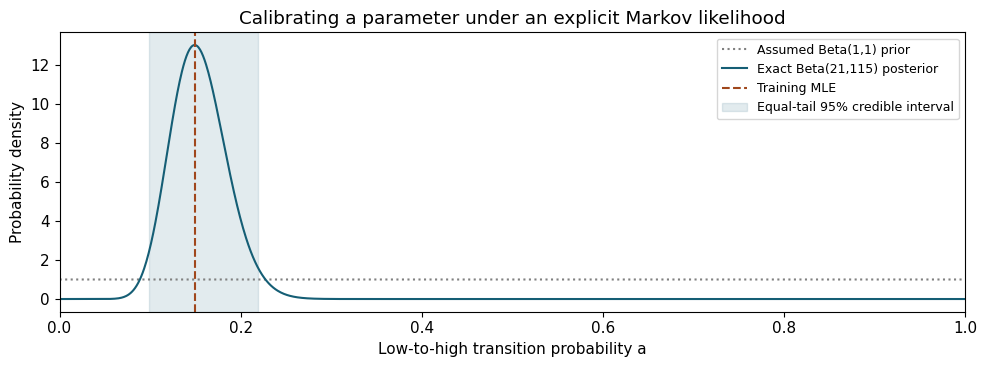

In [5]:
grid = np.linspace(0.0001, 0.9999, 1200)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(grid, beta_dist.pdf(grid, 1, 1), color="gray", ls=":", label="Assumed Beta(1,1) prior")
ax.plot(grid, beta_dist.pdf(grid, ALPHA, BETA), color="#155e75", label="Exact Beta(21,115) posterior")
ax.axvline(a_mle, color="#a0471c", ls="--", label="Training MLE")
ax.axvspan(*exact_ci, color="#155e75", alpha=0.12, label="Equal-tail 95% credible interval")
ax.set(xlabel="Low-to-high transition probability a", ylabel="Probability density",
       xlim=(0, 1), title="Calibrating a parameter under an explicit Markov likelihood")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 2. Build Metropolis–Hastings from the target density
For target density $\pi(\theta)$ and proposal density $q(\theta'\mid\theta)$, accept a proposal with probability

$$A(\theta,\theta')=\min\left\{1,\frac{\pi(\theta')q(\theta\mid\theta')}{\pi(\theta)q(\theta'\mid\theta)}\right\}.$$

The normalizing constant of $\pi$ cancels. This acceptance rule enforces detailed balance for the accepted moves, with rejections supplying self-transitions. Invariance is an algorithmic property; it does not establish that a finite run has explored the target well.

Use a **symmetric Gaussian random-walk proposal** $\theta'=\theta+\sigma Z$, $Z\sim N(0,1)$. Its proposal densities cancel. For the Beta target,

$$\log\widetilde\pi(\theta)=(\alpha-1)\log\theta+(\beta-1)\log(1-\theta),\quad0<\theta<1,$$

and $-\infty$ outside the support. Accept when

$$\log U<\min\{0,\log\widetilde\pi(\theta')-\log\widetilde\pi(\theta)\},\qquad U\sim\operatorname{Uniform}(0,1).$$

Propose on the whole real line and **reject** proposals outside $(0,1)$. Do not clip a proposal to a boundary or keep redrawing until it is in bounds: those operations change the proposal law, so the symmetry argument no longer applies unchanged.

Store the current state on **every iteration**, including rejections. Keeping accepted moves only produces a jump chain that generally has a different stationary distribution. The code consumes one normal and one uniform draw per proposal, with recorded seeds.

In [6]:
def metropolis(alpha, beta, start, scale, proposals=4000, seed=SEED):
    if not (alpha > 0 and beta > 0 and 0 < start < 1 and scale > 0 and proposals > 0):
        raise ValueError("Use positive shapes, scale, count, and an interior start")
    rng = np.random.default_rng(seed)
    states, accepted = np.empty(proposals), np.zeros(proposals, dtype=bool)
    log_target = lambda x: ((alpha-1)*np.log(x)+(beta-1)*np.log1p(-x)) if 0 < x < 1 else -np.inf
    current = log_target(start)
    for i in range(proposals):
        proposal = start + scale*rng.normal()
        proposed_log = log_target(proposal)
        log_u = np.log(rng.random())
        if log_u < min(0.0, proposed_log-current):
            start, current = proposal, proposed_log
            accepted[i] = True
        states[i] = start
    return states, accepted

Run four chains from dispersed starts $[.05,.25,.60,.90]$, with $\sigma=.05$. Each stores 4,000 **post-proposal states**; the initial value itself is not one of those 4,000 states. Discard the first 1,000 states of each chain as a prespecified warmup and retain 3,000 each.

Warmup is a practical attempt to reduce initialization bias, not a proof of convergence. We do not adapt the scale during these runs. Separate pseudorandom streams use seeds $6231,6232,6233,6234$; reproducibility does not imply independence of adjacent states within a chain.

In [7]:
STARTS = np.array([0.05, 0.25, 0.60, 0.90])
PROPOSALS, WARMUP, SCALE = 4000, 1000, 0.05
runs = [metropolis(ALPHA, BETA, x, SCALE, PROPOSALS, SEED+i) for i, x in enumerate(STARTS)]
all_chains = np.array([r[0] for r in runs])
accepts = np.array([r[1] for r in runs])
chains = all_chains[:, WARMUP:]
assert chains.shape == (4, 3000) and np.all((chains > 0) & (chains < 1))
print("Retained acceptance fractions:", np.round(accepts[:, WARMUP:].mean(axis=1), 3))

Retained acceptance fractions: [0.577 0.562 0.572 0.566]


### Trace plots ask whether the chains travel through the same region
A high acceptance fraction can mean a chain takes tiny steps. A low one can mean it repeats a state for a long time. Neither value alone measures adequate mixing. Compare traces across starts, posterior summaries, autocorrelation, and numerical error for the particular function being estimated. A universal acceptance target is not justified for this one-dimensional example.

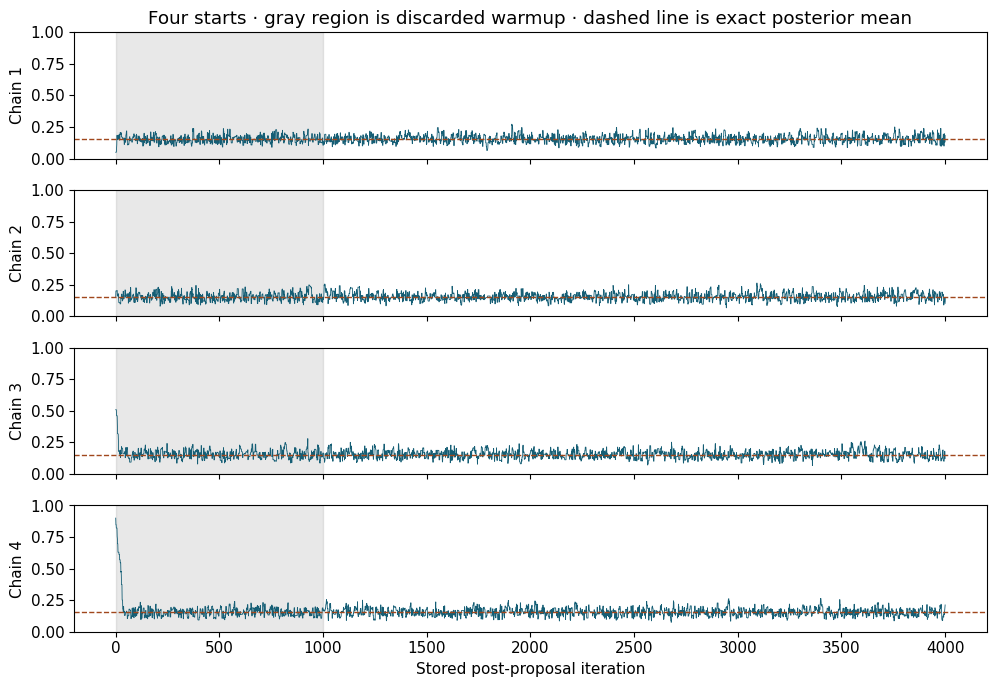

In [8]:
fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True, sharey=True)
for m, ax in enumerate(axes):
    ax.plot(np.arange(1, PROPOSALS+1), all_chains[m], color="#155e75", lw=0.6)
    ax.axvspan(0, WARMUP, color="gray", alpha=0.18)
    ax.axhline(exact_mean, color="#a0471c", ls="--", lw=1)
    ax.set(ylabel=f"Chain {m+1}", ylim=(0, 1))
axes[0].set_title("Four starts · gray region is discarded warmup · dashed line is exact posterior mean")
axes[-1].set_xlabel("Stored post-proposal iteration")
fig.tight_layout()
plt.show()

### A histogram can hide serial dependence
For a retained chain $x_1,\ldots,x_n$, estimate lag-$\ell$ autocorrelation by

$$\widehat\rho_\ell=\frac{\sum_{t=1}^{n-\ell}(x_t-\bar x)(x_{t+\ell}-\bar x)}{\sum_{t=1}^{n}(x_t-\bar x)^2}.$$

This descriptive estimate uses one common denominator, so $\widehat\rho_0=1$. Compute it **within** each chain; concatenating chains creates artificial boundary transitions. A constant chain has undefined autocorrelation, not evidence of independence. A marginal histogram can look plausible even when the chain is highly correlated.

In [9]:
def autocorrelation(values, max_lag=60):
    centered = np.asarray(values) - np.mean(values)
    denominator = centered @ centered
    if np.ptp(values) == 0 or denominator <= 0:
        return np.full(max_lag+1, np.nan)
    return np.array([centered[:len(centered)-lag] @ centered[lag:] / denominator
                     for lag in range(max_lag+1)])

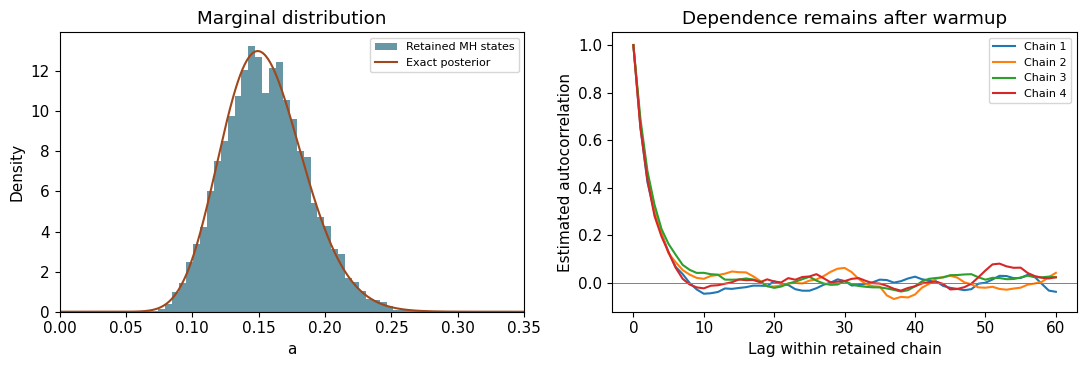

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(chains.ravel(), bins=40, density=True, color="#155e75", alpha=0.65, label="Retained MH states")
axes[0].plot(grid, beta_dist.pdf(grid, ALPHA, BETA), color="#a0471c", label="Exact posterior")
axes[0].set(xlim=(0, 0.35), xlabel="a", ylabel="Density", title="Marginal distribution")
for m, chain in enumerate(chains):
    axes[1].plot(autocorrelation(chain), label=f"Chain {m+1}")
axes[1].axhline(0, color="gray", lw=0.7)
axes[1].set(xlabel="Lag within retained chain", ylabel="Estimated autocorrelation", title="Dependence remains after warmup")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. Diagnose mixing without treating correlated draws as iid
Split each retained chain in half, producing $J=8$ half-chains of length $n_s=1500$. Let $\bar x_j$ and $s_j^2$ be their means and sample variances. The **basic, unranked split-$\widehat R$** taught here is

$$W=\frac1J\sum_js_j^2,\quad B=\frac{n_s}{J-1}\sum_j(\bar x_j-\bar x_{\cdot})^2,$$

$$\widehat V=\frac{n_s-1}{n_s}W+\frac{B}{n_s},\qquad\widehat R=\sqrt{\widehat V/W}.$$

Large values reveal disagreement between half-chains relative to variation inside them. A value near one is **not proof of convergence**, and finite-sample values can be slightly below one. We deliberately return infinity if any half-chain is constant rather than report a reassuring number for stuck chains.

This is a transparent classroom diagnostic. Modern **rank-normalized, folded split-$\widehat R$ and bulk/tail ESS** are different, stronger diagnostics, especially for heavy tails and differing scales. Use established implementations for substantive analysis; the basic calculation below does not replace them.

In [11]:
def basic_split_rhat(values):
    values = np.asarray(values, dtype=float)
    half = values.shape[1] // 2
    if half < 2:
        raise ValueError("Each chain needs at least four retained states")
    split = np.concatenate([values[:, :half], values[:, -half:]], axis=0)
    variances = split.var(axis=1, ddof=1)
    if np.any(variances <= 1e-30):
        return np.inf
    within = variances.mean()
    between = half * split.mean(axis=1).var(ddof=1)
    return np.sqrt(((half-1)*within/half + between/half) / within)

### Batch means estimate numerical uncertainty in a posterior mean
Posterior SD describes parameter uncertainty. **MCSE describes numerical error in an estimated posterior expectation** and can shrink with more effective computation. The iid formula $s/\sqrt{Mn}$ ignores within-chain correlation.

For a scalar function $f(a)$, partition each retained chain into $k$ nonoverlapping batches of length $L=50$; use $n_{\rm used}=kL$ states per chain. With batch means $\bar f_{mj}$, estimate each chain's asymptotic variance by

$$\widehat\sigma_{m,\rm asy}^{2}=L\,s^2_{\bar f_m},\qquad
\widehat{\operatorname{MCSE}}(\bar f)=\sqrt{\frac1{M^2}\sum_{m=1}^M\frac{\widehat\sigma_{m,\rm asy}^{2}}{n_{\rm used}}}.$$

The pooled mean below uses those same $n_{\rm used}$ states, dropping an incomplete trailing batch if necessary. With the default 3,000 states, all 60 batches are complete. The estimate assumes retained chains are near stationary, independent across streams, batches are long enough, and enough batches remain. **Poor mixing can make it badly misleading.** Examine batch-length sensitivity rather than treating $L=50$ as universal.

For the posterior mean of this same $f$, report a rough, function-specific effective sample size

$$\widehat{\rm ESS}_f=\frac{M^{-1}\sum_m s^2_{f,m}}{\widehat{\operatorname{MCSE}}(\bar f)^2}.$$

The numerator averages **within-chain** sample variances; it does not inflate the benchmark using separated chain means. We do not clip ESS to the number of draws. This teaching estimate is neither modern bulk ESS nor tail ESS, and it inherits the batch-means assumptions.

In [12]:
def batch_mean_summary(values, length=50):
    values = np.asarray(values, dtype=float)
    if length < 1 or int(length) != length:
        raise ValueError("Batch length must be a positive integer")
    m, n = values.shape
    k, used = n // length, (n // length)*length
    if k < 2:
        raise ValueError("Need at least two complete batches per chain")
    kept = values[:, :used]
    batch_means = kept.reshape(m, k, length).mean(axis=2)
    variance_mean = (length*batch_means.var(axis=1, ddof=1)/used).sum()/m**2
    valid = np.all(kept.var(axis=1, ddof=1) > 1e-30) and variance_mean > 0
    mcse = np.sqrt(variance_mean) if valid else np.nan
    ess = kept.var(axis=1, ddof=1).mean()/variance_mean if valid else np.nan
    return pd.Series({"pooled mean": kept.mean(), "batch MCSE": mcse, "rough mean ESS": ess,
                      "states used per chain": used, "batches per chain": k})

In [13]:
mean_report = batch_mean_summary(chains)
rhat = basic_split_rhat(chains)
display(mean_report.to_frame("f(a)=a").round(6))
print(f"Basic unranked split R-hat = {rhat:.5f}")
print(f"Exact posterior mean = {exact_mean:.6f}; exact posterior SD = {exact_sd:.6f}")
print(f"MH estimate minus exact mean = {chains.mean()-exact_mean:+.6f}")
print(f"WRONG iid SE for comparison = {chains.std(ddof=1)/np.sqrt(chains.size):.6f}")
assert abs(chains.mean()-exact_mean) < 8*mean_report["batch MCSE"]
assert np.isinf(basic_split_rhat(np.ones((4, 100))))

,f(a)=a
pooled mean,0.155389
batch MCSE,0.000630
rough mean ESS,2434.716230
states used per chain,3000.000000
batches per chain,60.000000


Basic unranked split R-hat = 1.00023
Exact posterior mean = 0.154412; exact posterior SD = 0.030872
MH estimate minus exact mean = +0.000977
WRONG iid SE for comparison = 0.000284


The exact mean is **0.154412** and the posterior SD is **0.030872**; neither is a mixing diagnostic. A small error for one seed does not validate the sampler. Conversely, MCSE is an estimated numerical error scale, not the realized error and not a bound on initialization bias. The generous eight-MCSE check is a smoke test against the known benchmark, not a theorem or a convergence criterion.

Do not routinely thin to make a trace look less dependent: discarding retained states usually wastes information when storage is not a constraint. More warmup, a longer run, a pleasing histogram, and a favorable acceptance fraction cannot by themselves certify adequate exploration.

### Deliberately challenge the proposal scale
Compare $\sigma=.001,.05,.40$ at the **same** number of proposal evaluations and the same four starting values. Tiny moves can accept almost everything while retaining memory of their starts. Large moves often leave the support or land in low-density regions and are rejected.

Record all diagnostics; no single threshold constitutes a pass. The small-scale example intentionally violates the near-stationarity assumption underlying the numerical MCSE and ESS calculation. Those values are printed to expose their limitation, **not to endorse uncertainty statements from a poorly mixed run**.

In [14]:
scale_chains, scale_rows = {}, []
for scale in [0.001, 0.05, 0.40]:
    scale_runs = [metropolis(ALPHA, BETA, x, scale, PROPOSALS, SEED+i) for i, x in enumerate(STARTS)]
    retained = np.array([r[0][WARMUP:] for r in scale_runs])
    scale_chains[scale] = retained
    report = batch_mean_summary(retained)
    scale_rows.append([scale, np.mean([r[1][WARMUP:].mean() for r in scale_runs]),
        retained.mean(), basic_split_rhat(retained), report["batch MCSE"], report["rough mean ESS"]])
scale_report = pd.DataFrame(scale_rows, columns=["scale", "acceptance", "mean", "basic split Rhat",
    "batch MCSE: provisional", "rough mean ESS: provisional"]).set_index("scale")
display(scale_report.round(6))

,acceptance,mean,basic split Rhat,batch MCSE: provisional,rough mean ESS: provisional
scale,,,,,
0.001,0.959917,0.325483,6.459830,0.002855,237.089970
0.050,0.569250,0.155389,1.000230,0.000630,2434.716230
0.400,0.092583,0.155542,1.004304,0.001021,877.071861


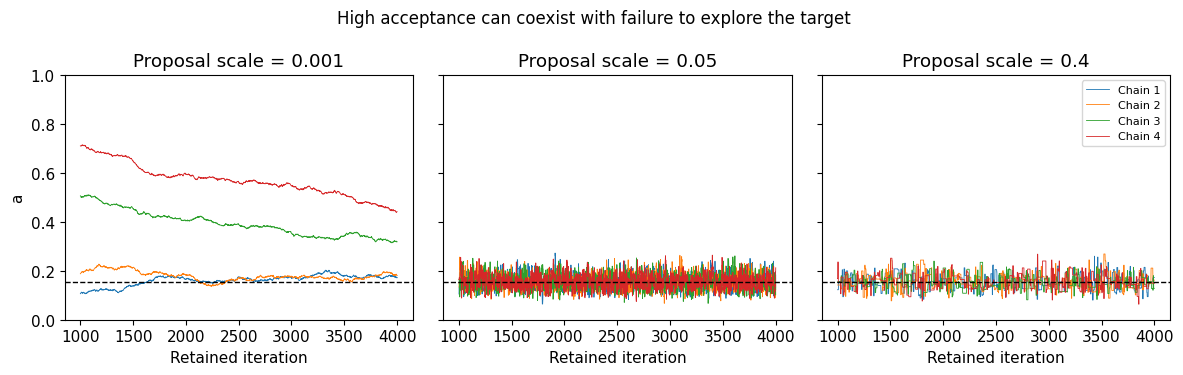

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (scale, retained) in zip(axes, scale_chains.items()):
    for m, chain in enumerate(retained):
        ax.plot(np.arange(WARMUP+1, PROPOSALS+1), chain, lw=0.6, label=f"Chain {m+1}")
    ax.axhline(exact_mean, color="black", ls="--", lw=1)
    ax.set(xlabel="Retained iteration", ylim=(0, 1), title=f"Proposal scale = {scale:g}")
axes[0].set_ylabel("a")
axes[-1].legend(fontsize=8)
fig.suptitle("High acceptance can coexist with failure to explore the target", fontsize=12)
fig.tight_layout()
plt.show()

### Verify algorithmic invariants and a solvable target
A rejection must repeat the previous state; all states must stay in support; rerunning a recorded seed must reproduce states and acceptance decisions. Test those properties directly. Direct independent Beta draws provide an additional benchmark that is available because this example is conjugate.

These checks expose implementation errors. They do not prove finite-run convergence or make the homogeneous bike model correct. In harder applications, use multiple dispersed starts, modern diagnostics, function-specific MCSE, and sensitivity checks together.

In [16]:
replay, replay_accept = metropolis(ALPHA, BETA, STARTS[0], SCALE, PROPOSALS, SEED)
assert np.array_equal(replay, all_chains[0]) and np.array_equal(replay_accept, accepts[0])
previous = np.r_[STARTS[0], replay[:-1]]
assert np.array_equal(replay[~replay_accept], previous[~replay_accept])
assert np.all((replay > 0) & (replay < 1))
assert np.count_nonzero(~replay_accept) > 0
independent_beta = np.random.default_rng(SEED+100).beta(ALPHA, BETA, chains.size)
assert abs(independent_beta.mean()-exact_mean) < 6*exact_sd/np.sqrt(chains.size)
print(f"Direct Beta mean = {independent_beta.mean():.6f} (independent draws)")
print("Storage, support, reproducibility, and direct-sampling benchmark checks passed.")

Direct Beta mean = 0.154840 (independent draws)
Storage, support, reproducibility, and direct-sampling benchmark checks passed.


## 4. Propagate parameter uncertainty into a first-passage prediction
Starting low, let $T$ be the number of days until the first high day. Under the homogeneous model with fixed $a$,

$$p_H(a)=P(T>H\mid a,Y_{\rm start}=0)=(1-a)^H.$$

This is **no high day anywhere in the next $H$ days**, not merely a low state on day $H$. Parameter $b$ is irrelevant before the first hit. For $a\mid Y\sim\operatorname{Beta}(\alpha,\beta)$,

$$P(T>H\mid Y,Y_{\rm start}=0)=E[(1-a)^H\mid Y]
=\frac{B(\alpha,\beta+H)}{B(\alpha,\beta)}
=\prod_{j=0}^{H-1}\frac{\beta+j}{\alpha+\beta+j}.$$

Average the transformed MH states to approximate this expectation; do not transform their mean. For $H>1$ the function is convex, so Jensen's inequality gives $E[(1-a)^H]\ge(1-E[a])^H$. The two quantities are not equal in general. Calculate a new batch-means MCSE for **the transformed function**.

In [17]:
H = 30
exact_tail = np.prod((BETA+np.arange(H))/(ALPHA+BETA+np.arange(H)))
second_tail_moment = np.prod((BETA+np.arange(2*H))/(ALPHA+BETA+np.arange(2*H)))
tail_posterior_sd = np.sqrt(second_tail_moment-exact_tail**2)
tail_states = (1-chains)**H
tail_report = batch_mean_summary(tail_states)
tail_ci = (1-exact_ci[::-1])**H
plugin_posterior_mean, plugin_mle = (1-exact_mean)**H, (1-a_mle)**H
assert np.isclose(exact_tail, 0.01082405765925871)
assert exact_tail > plugin_posterior_mean
assert abs(tail_states.mean()-exact_tail) < 8*tail_report["batch MCSE"]
print(f"Exact integrated tail={exact_tail:.8f}; MH mean={tail_states.mean():.8f}")
print(f"Plug-in posterior mean={plugin_posterior_mean:.8f}; plug-in MLE={plugin_mle:.8f}")
print("Exact 95% credible interval for the model tail probability:", np.round(tail_ci, 8))

Exact integrated tail=0.01082406; MH mean=0.01055191
Plug-in posterior mean=0.00652782; plug-in MLE=0.00783433
Exact 95% credible interval for the model tail probability: [0.00059069 0.0439069 ]


For $H=30$, integration gives **0.010824**, compared with **0.006528** at the posterior-mean parameter and **0.007834** at the MLE. More precise MCMC should approach the integrated answer, not either plug-in value.

The posterior distribution of $p_{30}(a)$ describes uncertainty about a **model probability**. Since the transformation decreases with $a$, its equal-tail credible interval is $[(1-a_{.975})^{30},(1-a_{.025})^{30}]$, about **[0.000591, 0.043907]**. This is not a predictive interval for the binary future event, not an MC error interval, and not an interval for the observed overlapping-window fraction.

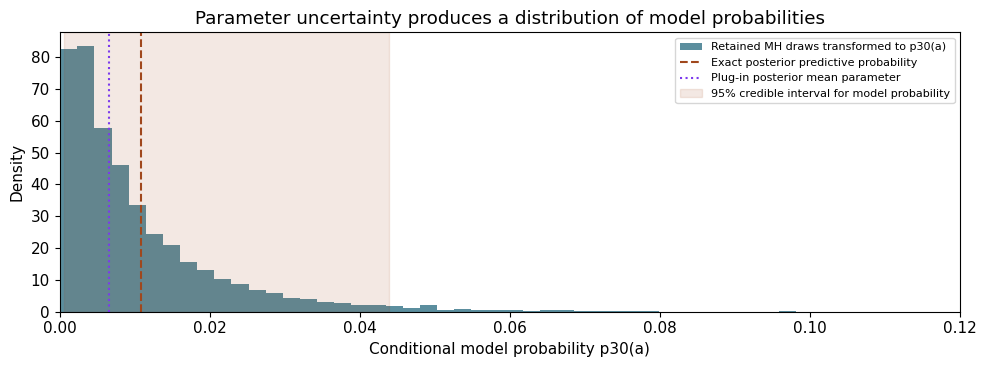

In [18]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(tail_states.ravel(), bins=60, density=True, color="#155e75", alpha=0.7,
        label="Retained MH draws transformed to p30(a)")
ax.axvline(exact_tail, color="#a0471c", ls="--", label="Exact posterior predictive probability")
ax.axvline(plugin_posterior_mean, color="#7c3aed", ls=":", label="Plug-in posterior mean parameter")
ax.axvspan(*tail_ci, color="#a0471c", alpha=0.12, label="95% credible interval for model probability")
ax.set(xlabel="Conditional model probability p30(a)", ylabel="Density", xlim=(0, 0.12),
       title="Parameter uncertainty produces a distribution of model probabilities")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Match each uncertainty number to its target
The posterior SD of $a$ and the posterior SD of $p_{30}(a)$ remain even if an expectation is computed exactly. Their mean-estimation MCSEs measure only finite MCMC computation and depend on the transformed chain's serial correlation. The two posterior SDs have different scales, as do their MCSEs.

Repeat the batch calculation with lengths 25, 50, and 100. A stable-looking table is useful evidence, but not proof that all long-range dependence has been captured. If changing batch length, run length, starts, or proposal scale materially changes the conclusion, investigate before interpreting a credible interval or posterior prediction.

In [19]:
uncertainty = pd.DataFrame({"parameter a": [exact_sd, mean_report["batch MCSE"], mean_report["rough mean ESS"]],
    "model tail p30(a)": [tail_posterior_sd, tail_report["batch MCSE"], tail_report["rough mean ESS"]]},
    index=["Exact posterior SD", "MCSE of estimated posterior mean", "Rough function-specific mean ESS"])
display(uncertainty.round(6))
sensitivity = pd.DataFrame({length: [batch_mean_summary(chains, length)["batch MCSE"],
    batch_mean_summary(tail_states, length)["batch MCSE"]] for length in [25, 50, 100]},
    index=["MCSE: mean a", "MCSE: mean p30(a)"])
display(sensitivity.round(6))

,parameter a,model tail p30(a)
Exact posterior SD,0.030872,0.012044
MCSE of estimated posterior mean,0.000630,0.000219
Rough function-specific mean ESS,2434.716230,2854.528255


,25,50,100
MCSE: mean a,0.000603,0.000630,0.000666
MCSE: mean p30(a),0.000213,0.000219,0.000222


## 5. Bayesian computation does not repair a model-data mismatch
Revisit actual 30-day windows using origins from August 31 onward, retaining only observed low-state origins with complete follow-up through day 30. The August 31 origin is high and drops out. No fitting uses the September–December outcomes.

For each selected origin, record whether **all next 30 days remain low**. Overlapping windows share days and are dependent. Complete follow-up resolves dataset-end censoring for this finite-horizon event; it does not create independent trials. We do not place an iid binomial error bar on the observed fraction or treat it as a new likelihood after inspecting it.

In [20]:
origins = np.arange(len(train)-1, len(bike)-H)
origins = origins[y_all[origins] == 0]
windows = np.array([y_all[i+1:i+H+1] for i in origins])
observed_tail = ~windows.any(axis=1)
assert len(origins) == 44 and observed_tail.sum() == 16
assert (origins >= 242).all() and (origins+H <= 364).all()
assert bike["dteday"].iloc[origins[0]] == pd.Timestamp("2011-09-05")
assert bike["dteday"].iloc[origins[-1]] == pd.Timestamp("2011-12-01")
print(f"Observed tail windows: {observed_tail.sum()}/{len(origins)} = {observed_tail.mean():.6f}")
print("First and last origins:", bike["dteday"].iloc[origins[[0, -1]]].dt.strftime("%Y-%m-%d").tolist())

Observed tail windows: 16/44 = 0.363636
First and last origins: ['2011-09-05', '2011-12-01']


In [21]:
development_report = pd.Series({"Training MLE plug-in": plugin_mle,
    "Exact posterior predictive probability": exact_tail,
    "MH estimate of posterior predictive probability": tail_states.mean(),
    "MCSE of MH prediction computation only": tail_report["batch MCSE"],
    "Observed dependent-window fraction": observed_tail.mean()})
display(development_report.to_frame("H=30").round(6))

,H=30
Training MLE plug-in,0.007834
Exact posterior predictive probability,0.010824
MH estimate of posterior predictive probability,0.010552
MCSE of MH prediction computation only,0.000219
Observed dependent-window fraction,0.363636


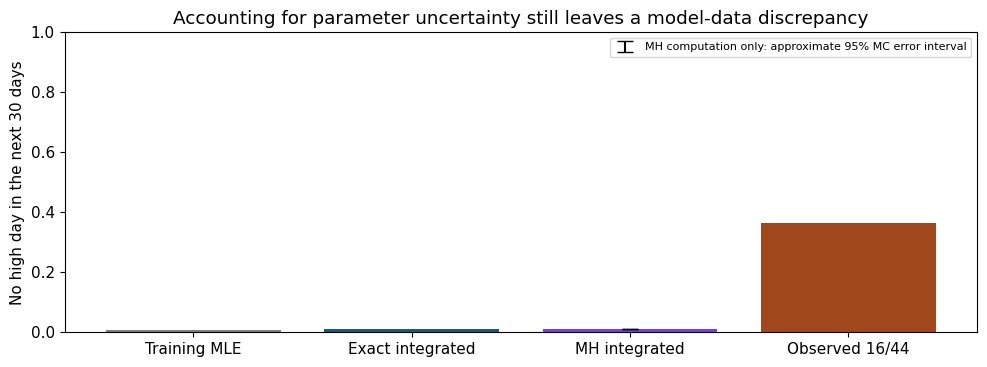

In [22]:
fig, ax = plt.subplots(figsize=(10, 3.8))
values = [plugin_mle, exact_tail, tail_states.mean(), observed_tail.mean()]
ax.bar(np.arange(4), values, color=["gray", "#155e75", "#7c3aed", "#a0471c"])
ax.errorbar(2, values[2], yerr=1.96*tail_report["batch MCSE"], fmt="none", color="black",
            capsize=6, label="MH computation only: approximate 95% MC error interval")
ax.set(xticks=np.arange(4), xticklabels=["Training MLE", "Exact integrated", "MH integrated", "Observed 16/44"],
       ylabel="No high day in the next 30 days", ylim=(0, 1),
       title="Accounting for parameter uncertainty still leaves a model-data discrepancy")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The observed **16/44 = 0.3636** contrasts with the posterior predictive probability **0.010824**. The model-probability credible interval and MCMC error interval answer different questions and do not establish predictive calibration for these dependent observed windows. The numerical error bar above is only an approximate CLT-based statement about estimating a posterior expectation, conditional on adequate mixing and batch-means assumptions.

A posterior can be precisely computed under a poorly fitting model. Homogeneity, the state definition, priors, calendar effects, and reuse of the development period still require scrutiny. This discrepancy motivates substantive revision and fresh validation; it does not identify a causal mechanism or justify claims about lost customers.

**AI verification:** Require a stated target density, proposal law, acceptance ratio, rejection-storage rule, data-fitting boundary, and diagnostic definition. Check against conjugate results before trusting generated code. AI use is optional; disclose assistance and the claims you independently tested.

In [23]:
assert np.array_equal(N, [[114, 20], [19, 89]])
assert np.array_equal(origins, np.arange(242, 335)[y_all[242:335] == 0])
assert np.isclose(plugin_mle, 0.007834325094603712)
assert np.isclose(np.trapz((1-grid)**H*beta_dist.pdf(grid, ALPHA, BETA), grid), exact_tail)
assert np.allclose(tail_ci, (1-beta_dist.ppf([0.975, 0.025], ALPHA, BETA))**H)
assert basic_split_rhat(scale_chains[0.001]) > basic_split_rhat(chains)
assert scale_report.loc[0.001, "acceptance"] > scale_report.loc[0.05, "acceptance"]
assert np.isnan(batch_mean_summary(np.ones((4, 100)))["batch MCSE"])
print("Passed: frozen-data, posterior, predictive-transform, poor-mixing, and constant-chain checks.")
assert np.isnan(autocorrelation(np.full(100, 0.1))).all()

Passed: frozen-data, posterior, predictive-transform, poor-mixing, and constant-chain checks.


## Exercise 1 — Calibrate the other transition (6–8 minutes)
Use the **high-to-low parameter $b$**, keeping the training boundary fixed.

1. Derive its conditional likelihood and posterior under a Beta(1,1) prior. Report the exact posterior mean, SD, and equal-tail 95% credible interval, explaining why the daily states were not modeled as iid.
2. Run four MH chains with scale **.02**, starts $[.05,.25,.60,.90]$, 4,000 proposals, 1,000 warmup states, and recorded seeds. Compare the mean and histogram with exact/direct Beta benchmarks; inspect traces, basic split-$\widehat R$, batch MCSE, and function-specific rough ESS.
3. Replace only $b$'s prior by **Beta(2,2)**. Derive the new posterior and compare its mean and credible interval. State which modeling assumptions remain untested by accurate computation.

In [24]:
# Your b-posterior derivation, MH benchmarks, diagnostics, and prior sensitivity.
pass

## Exercise 2 — Acceptance is not a mixing certificate (6–8 minutes)
Keep $a$'s Beta(21,115) target and the four dispersed starts.

1. Compare scales **.002, .02, and .20** with 4,000 proposals and 1,000 warmup states per chain. Report acceptance, traces, exact-mean error, basic split-$\widehat R$, and provisional batch MCSE/rough mean ESS. State where their assumptions are doubtful.
2. For scale .02, recompute batch MCSE with batch lengths **25, 100, and 200**, using the same retained states and explicitly reporting the number used. Explain why larger batches trade fewer batch means for potentially less between-batch dependence.
3. Explain why accepted-only storage, routinely thinning the chain, or discarding more warmup without inspecting exploration would not solve every mixing problem. Describe what evidence would make you increase computation or change the proposal.

In [25]:
# Your proposal-scale challenge, batch-length sensitivity, and diagnostic interpretation.
pass

## Exercise 3 — Integrate a nonlinear prediction (6–8 minutes)
Change the first-passage horizon to **$H=14$**, still starting low.

1. Derive and compute the exact posterior predictive tail $E[(1-a)^{14}\mid Y]$. Compare it with the posterior-mean plug-in and training-MLE plug-in; explain the direction of the Jensen gap.
2. Estimate the integrated prediction using the retained MH states and compute a **new** batch-means MCSE for that transformed function. Report an exact 95% credible interval for $p_{14}(a)$ and distinguish it from posterior predictive variability and computational uncertainty.
3. Construct complete low-origin 14-day development windows. Report the observed no-high fraction, origin count, and first/last dates. Preserve the original fitting boundary and explain why overlapping windows do not admit the iid MCSE formula.

In [26]:
# Your H=14 integration, function-specific numerical uncertainty, and observed-window check.
pass

## Exercise 4 — Audit generated MCMC code (7–10 minutes)
An assistant proposes:

```python
proposal = np.clip(current + sigma*rng.normal(), 0.001, 0.999)
if rng.random() < min(1, target(proposal)/target(current)):
    current = proposal
    draws.append(current)  # save accepted moves only
se = np.std(draws, ddof=1) / np.sqrt(len(draws))
# "Acceptance above 95% and R-hat near 1 prove convergence; refit on all days."
```

1. Identify the changed proposal law, storage bias, inappropriate iid SE, diagnostic overclaim, and violated data boundary. Repair the sampler and document its target and proposal law.
2. Give discriminating checks for rejected states, support, reproducibility, and the exact Beta benchmark. Include a deliberately stuck or nearly stuck example; a plot that looks smooth is insufficient.
3. Explain why accurate Bayesian computation cannot by itself fix the 30-day observed-window discrepancy. Distinguish model uncertainty, posterior uncertainty, and Monte Carlo error. Disclose any AI assistance and the checks you performed.

In [27]:
# Your repaired sampler, discriminating checks, and uncertainty/data-boundary audit.
pass

## Checkpoint and project connection
Explain without code why rejection can be essential to correct MCMC; why high acceptance is not sufficient; why a credible interval and MCSE have different meanings; and why the exact integrated prediction differs from a plug-in prediction.

Save these four short responses as **Concept Lab 3, Part A** and combine them with Module 6's Part B for the week-6 submission. Continue the single course project: name a parameter, justify its likelihood and prior, identify an exact or simplified benchmark, and plan mixing and model-adequacy checks. Do not add a new substantial project or use MCMC when a simpler adequate method is available.

The six figures separate parameter posteriors, correlated simulation states, first-passage prediction, and actual observations. For diagnostics beyond this teaching implementation, see [Vehtari et al., rank normalization, folding, and localization](https://doi.org/10.1214/20-BA1221) and the [Stan reference discussion of effective sample size](https://mc-stan.org/docs/reference-manual/analysis.html). These references extend the basic calculations here; they do not turn a finite-run diagnostic into proof.

In [28]:
print("Python", platform.python_version())
for package in ["numpy", "pandas", "scipy", "matplotlib", "nbformat", "nbclient"]:
    print(package, metadata.version(package))
print("Base seed:", SEED, "| proposals/chain:", PROPOSALS, "| warmup:", WARMUP)
print("Starts:", STARTS, "| scale:", SCALE, "| batch length:", 50)
print("CSV SHA-256:", hashlib.sha256(csv_path.read_bytes()).hexdigest())
print("Completed: MH storage, posterior benchmarks, mixing, predictive integration, and data checks.")

Python 3.10.9
numpy 1.24.2
pandas 2.0.0
scipy 1.10.1
matplotlib 3.7.1
nbformat 5.7.0
nbclient 0.5.13
Base seed: 6231 | proposals/chain: 4000 | warmup: 1000
Starts: [0.05 0.25 0.6  0.9 ] | scale: 0.05 | batch length: 50
CSV SHA-256: fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329
Completed: MH storage, posterior benchmarks, mixing, predictive integration, and data checks.
